In [1]:
import glob
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

import numpy as np

def calculate_djf_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_djf = ds_seasons.sel(time=(ds_seasons['time.season'] == 'DJF'))
    ds_djf['time'] = pd.date_range(str(ds_djf.time[0].values).split('-')[0], str(int(str(ds_djf.time[-1].values).split('-')[0]) +1), freq='YS-FEB',unit='s')
    return ds_djf


def anomaly_calculation(model, clim):
    ano_list = []
    for i in range(1,13):
        ano_list.append(model.sel(time=model.time[model.time.dt.month.isin(i)]) - clim.sel(month=i))
    return xr.concat(ano_list, dim='time').sortby('time')


def load_climatology(path):
    clim = xr.open_dataset(glob.glob(path)[0])
    clim['time'] = [1,2,3,4,5,6,7,8,9,10,11,12]
    clim = clim.rename({'time': 'month'})
    return clim

def load_data(path):
    ens = []
    ds = []
    for p in glob.glob(path):
        ens.append(p.split('/')[-1].split('_')[4])
        ds.append(xr.open_dataset(p))
    data = xr.concat(ds, dim='ens')
    data['ens'] = ens

    return data

def pressure_weighting(data, plevs=slice(7000,2000)):
    # here I select the pressure level intervall 
    # for which I want to caluculate the layer weights
    # (in this case plevs = 70 - 20 hPa)
    data = data.sel(plev=plevs)
    # Then natural logarithm of this pressure values is caluculated
    log_pressure = np.log(data.plev.values)  
    # the difference between this logaritmic pressure values is made
    log_layer_thickness = np.abs(np.diff(log_pressure))
    # then i devide these differences by the total thickness of the layer
    # = sum of the differences
    log_layer_thickness = log_layer_thickness / sum(log_layer_thickness)

    # this part just creates an array to make it compatible with the data 
    # #(no manipulation of the results done in this step)
    log_layer_thickness = xr.DataArray(
        log_layer_thickness,
        coords={"plev": data.plev.values[:-1]},  # Assign to the lower pressure level of each layer
        dims=["plev"]
    )

    # finally I multiply the data with the "normalized" thickness of the pressure layer
    data = data * log_layer_thickness

    return data.sum(dim='plev')

In [2]:

path = "/sto4/data/Intermediate/VolMIP/pinatubo-full/"
path_piControl = "/sto4/data/Intermediate/VolMIP/piControl/"
models = ['CanESM5', 'GISS-E2-1-G','MPI-ESM1-2-LR', 'MIROC-ES2L', 'UKESM1-0-LL']
plotdir = '/home/kperny/VolMIP_stratosphere/plots/wterm_analysis/'

enso_nao_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_enso_flags.csv')
enso_nao_flags = enso_nao_flags.set_index(['model', 'realization'])

In [3]:
# calculation for piControl
model = 'CanESM5'
wtem_clim_pi = load_climatology(path_piControl + model + '/wtem_clim_EmonZ*')
ta_clim_pi = load_climatology(path_piControl + model + '/ta_clim_AmonZ*')

ta_tmp = xr.open_dataset(glob.glob(path_piControl + model + '/ta_AmonZ*.nc')[0], decode_times=time_coder)
ta_ano = anomaly_calculation(ta_tmp, ta_clim_pi)
ta_piControl = calculate_djf_mean(ta_ano)

wtem_tmp = xr.open_dataset(glob.glob(path_piControl + model + '/wtem_EmonZ*.nc')[0], decode_times=time_coder)
wtem_ano = anomaly_calculation(wtem_tmp, wtem_clim_pi)
wtem_piControl = calculate_djf_mean(wtem_ano)

enso_nao_flags.loc[model,'deltaT_tropics'] = pressure_weighting(ta_piControl.sel(time = enso_nao_flags.loc[model]['year'].values, method='nearest').ta.sel(lat=slice(-20,20)).mean('lat')).squeeze().values
enso_nao_flags.loc[model,'deltaT_polar'] = pressure_weighting(ta_piControl.sel(time = enso_nao_flags.loc[model]['year'].values, method='nearest').ta.sel(lat=slice(70,90)).mean('lat')).squeeze().values
enso_nao_flags.loc[model,'deltaWtem'] = wtem_piControl.sel(time = enso_nao_flags.loc[model]['year'].values, method='nearest').wtem.sel(lat=slice(55,65), plev=1000).mean('lat').squeeze().values
enso_nao_flags = enso_nao_flags.loc[model]

/tmp/ipykernel_2355001/1070168184.py:27: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  clim = xr.open_dataset(glob.glob(path)[0])
/tmp/ipykernel_2355001/1070168184.py:27: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  clim = xr.open_dataset(glob.glob(path)[0])
/tmp/ipykernel_2355001/1070168184.py:22: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ano_list.ap

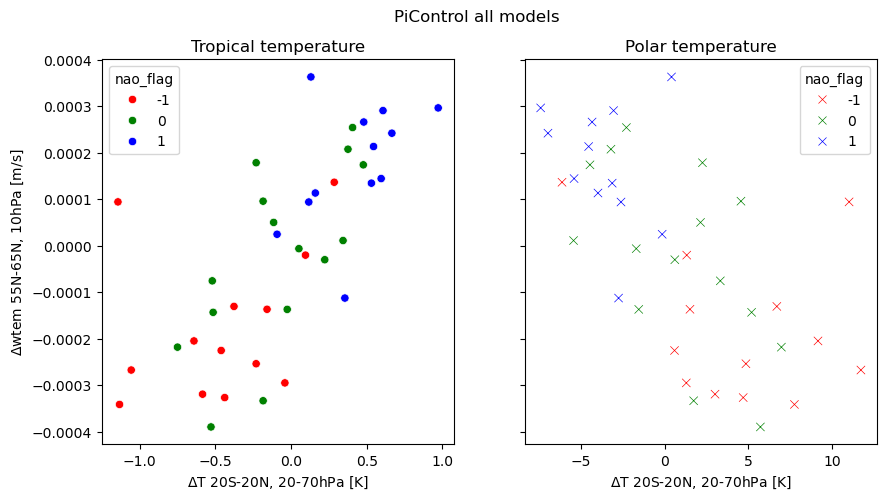

In [4]:
fig, axs = plt.subplots(1,2, figsize=(10,5), sharey=True)
sns.scatterplot(enso_nao_flags.reset_index(), x='deltaT_tropics', y='deltaWtem', hue='nao_flag', palette=['red', 'green', 'blue'], ax=axs[0])
sns.scatterplot(enso_nao_flags.reset_index(), x='deltaT_polar', y='deltaWtem', hue='nao_flag', palette=['red', 'green', 'blue'], marker='x', ax=axs[1])
plt.suptitle('PiControl all models')
axs[0].set_title('Tropical temperature')
axs[1].set_title('Polar temperature')
axs[0].set_ylabel('$\Delta$wtem 55N-65N, 10hPa [m/s]')
axs[0].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]')
axs[1].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]')

plt.savefig(plotdir + model + '_wtem_piControl.png', dpi=200)

In [5]:
volc_nao_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_change.csv')
volc_nao_flags = volc_nao_flags.set_index(['model', 'realization'])
df_volc = volc_nao_flags.where(volc_nao_flags.experiment=='volc').dropna().drop('experiment', axis=1)


ta_volc = load_data(path + model + '/ta_AmonZ_*fixed_dates.nc')
wtem_volc = load_data(path + model + '/wtem_EmonZ_*fixed_dates.nc')
wtem_clim_pi = load_climatology(path_piControl + model + '/wtem_clim_EmonZ*')
ta_clim_pi = load_climatology(path_piControl + model + '/ta_clim_AmonZ*')

ta_ano = anomaly_calculation(ta_volc['ta'], ta_clim_pi['ta'])
ta_volc = calculate_djf_mean(ta_ano)

wtem_ano = anomaly_calculation(wtem_volc['wtem'], wtem_clim_pi['wtem'])
wtem_volc = calculate_djf_mean(wtem_ano)

df_volc.loc[model,'deltaT_tropics'] = pressure_weighting(ta_volc.sel(time='1992-02')).sel(lat=slice(-20,20)).mean('lat').squeeze().sel(ens=df_volc.loc[model].index).values
df_volc.loc[model,'deltaT_polar'] = pressure_weighting(ta_volc.sel(time='1992-02')).sel(lat=slice(70,90)).mean('lat').squeeze().sel(ens=df_volc.loc[model].index).values
# df_volc.loc[model,'deltaWtem'] = pressure_weighting(wtem_volc.sel(time='1992-02')).sel(lat=slice(60,80)).mean('lat').squeeze().sel(ens=df_volc.loc[model].index).values
df_volc.loc[model,'deltaWtem'] = pressure_weighting(wtem_volc.sel(time='1992-02')).sel(lat=slice(80,90)).mean('lat').squeeze().sel(ens=df_volc.loc[model].index).values

df_volc = df_volc.loc[model]

/tmp/ipykernel_2355001/1070168184.py:27: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  clim = xr.open_dataset(glob.glob(path)[0])
/tmp/ipykernel_2355001/1070168184.py:27: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  clim = xr.open_dataset(glob.glob(path)[0])


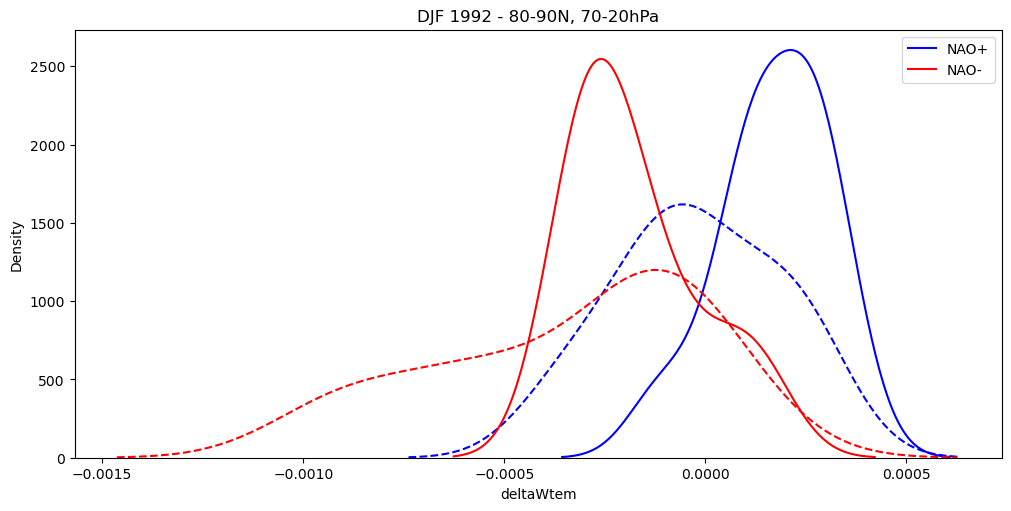

In [6]:
fig, axs = plt.subplots(1,1, figsize=(10,5), layout='constrained')
posnao_pi = enso_nao_flags.where(enso_nao_flags.nao_flag == 1).dropna()
negnao_pi = enso_nao_flags.where(enso_nao_flags.nao_flag == -1).dropna()

posnao_volc = df_volc.where(df_volc.nao_flag == 1).dropna()
negnao_volc = df_volc.where(df_volc.nao_flag == -1).dropna()

sns.kdeplot(posnao_pi, x='deltaWtem', color='blue', label='NAO+')
sns.kdeplot(posnao_volc, x='deltaWtem',color='blue', linestyle='--')
sns.kdeplot(negnao_pi, x='deltaWtem', color='red', label='NAO-')
sns.kdeplot(negnao_volc, x='deltaWtem', color='red', linestyle='--')

plt.legend()
plt.title('DJF 1992 - 80-90N, 70-20hPa')
plt.savefig(plotdir + model + '_wtem_distribution_8090.png', dpi=200)

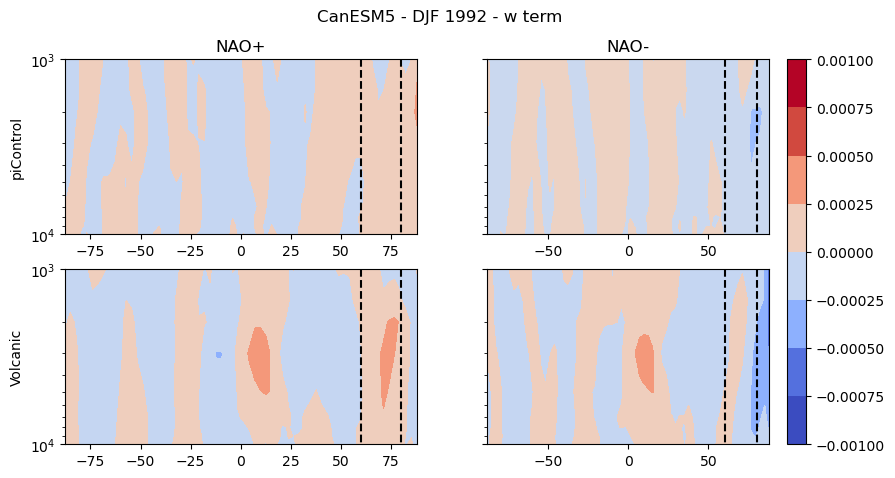

In [7]:
fig, axs = plt.subplots(2,2,figsize=(10,5), sharey=True)

naop = wtem_piControl.wtem.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == 1).dropna().year.values).mean('time')
cbar = axs[0,0].contourf(naop.lat, naop.plev, naop, cmap='coolwarm', vmin=-0.00075, vmax=0.00075)
naon = wtem_piControl.wtem.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == -1).dropna().year.values).mean('time')
axs[0,1].contourf(naon.lat, naon.plev, naon, cmap='coolwarm', vmin=-0.00075, vmax=0.00075)

naop = wtem_volc.sel(ens=df_volc.where(df_volc.nao_flag == 1).dropna().index).sel(time='1992-02').squeeze().mean('ens')
axs[1,0].contourf(naop.lat, naop.plev, naop, cmap='coolwarm', vmin=-0.00075, vmax=0.00075)
naon = wtem_volc.sel(ens=df_volc.where(df_volc.nao_flag == -1).dropna().index).sel(time='1992-02').squeeze().mean('ens')
axs[1,1].contourf(naon.lat, naon.plev, naon, cmap='coolwarm', vmin=-0.00075, vmax=0.00075)

axs[0,0].vlines([60, 80], 1000, 10000, color='k', linestyle=['--', '--', '-.'])
axs[1,0].vlines([60, 80], 1000, 10000, color='k', linestyle=['--', '--', '-.'])
axs[0,1].vlines([60, 80], 1000, 10000, color='k', linestyle=['--', '--', '-.'])
axs[1,1].vlines([60, 80], 1000, 10000, color='k', linestyle=['--', '--', '-.'])

axs[0,0].set_title('NAO+')
axs[0,1].set_title('NAO-')
axs[0,0].set_ylabel('piControl')
axs[1,0].set_ylabel('Volcanic')
axs[0,0].set_ylim(10000, 1000)
axs[0,0].set_yscale('log')

plt.suptitle(model + ' - DJF 1992 - w term')
plt.colorbar(cbar, ax=axs[0:2,1])
plt.savefig(plotdir + model + '_wtem_contour.png', dpi=200)

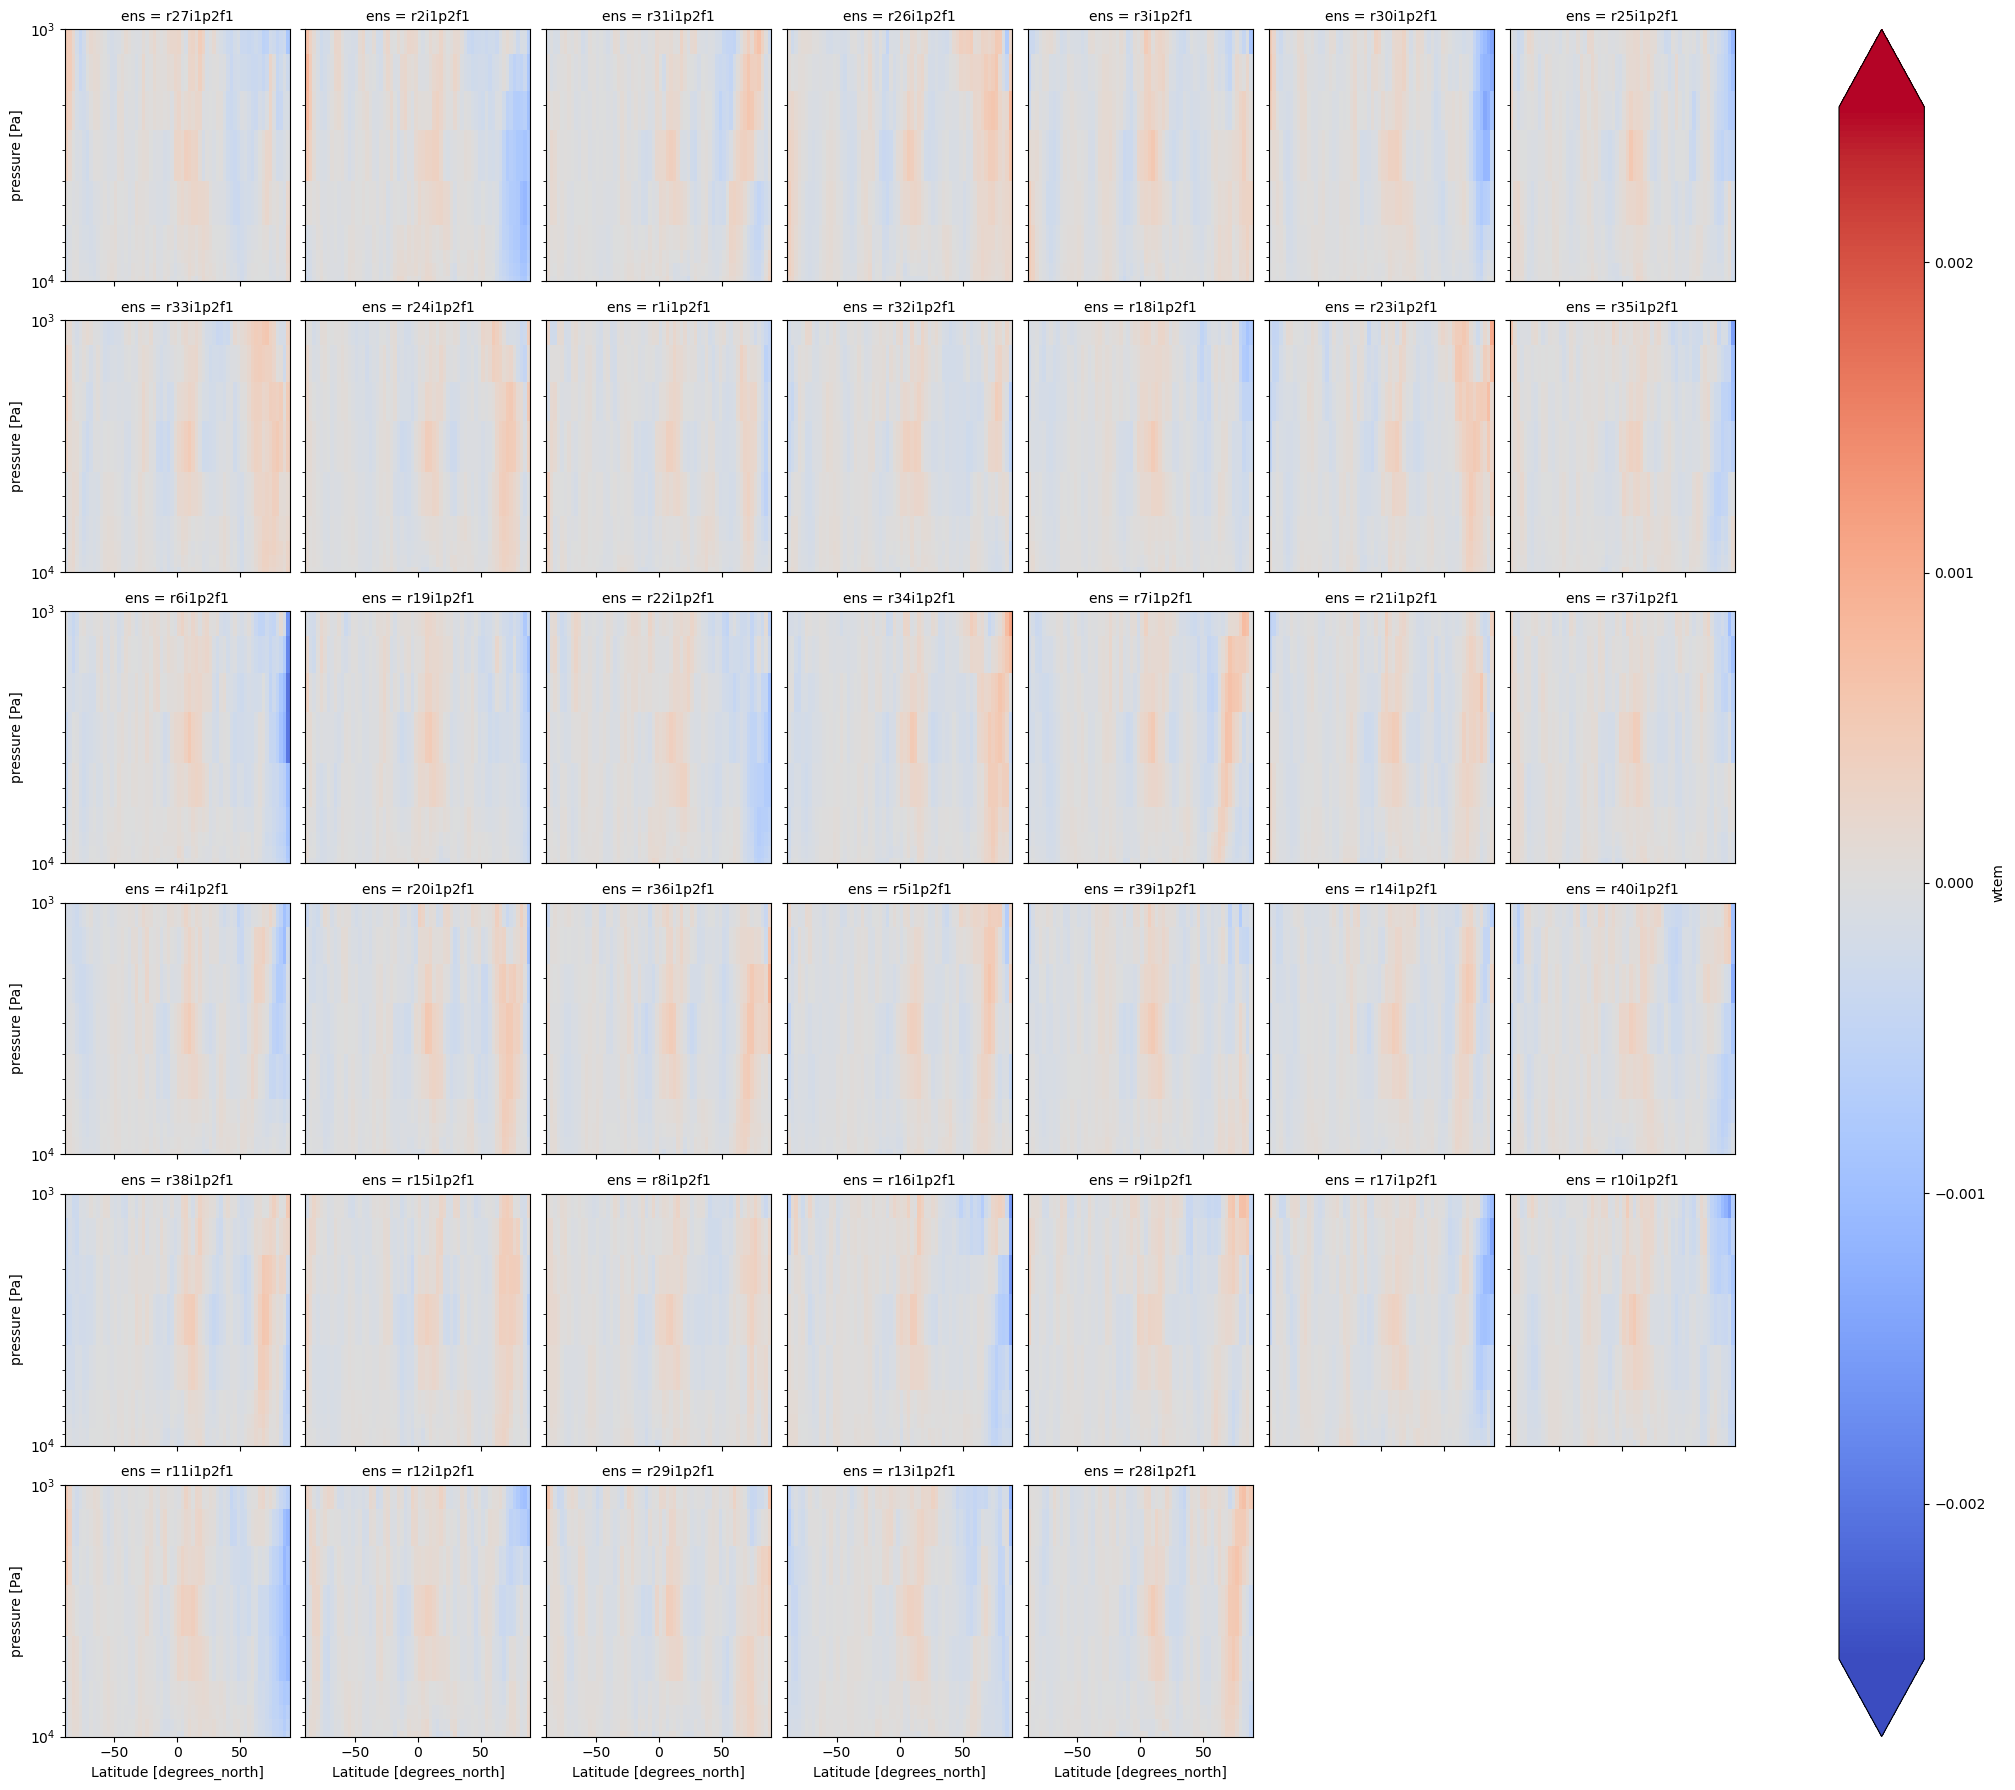

In [27]:
wtem_volc.sel(time='1992-02').squeeze().plot(x='lat', y='plev', col='ens', col_wrap=7, cmap='coolwarm', vmin=-0.0025, vmax=0.0025)
#plt.axvline(55, color='black', linestyle='--')
#plt.axvline(70, color='black', linestyle='-.')
plt.ylim(10000, 1000)
plt.yscale('log')